![Banner](../images/09_03_banner_rs_rader.png)


# Interferometric Coherence of SLCs

This notebook explains interferometric coherence, the pixel-by-pixel similarity of two SLC images taken at different times, walks through the processing workflow, and computes coherence for a real Sentinel-1 pair over Mexico City.


## Overview

Interferometric coherence is a measure of how similar two radar images (SLCs, or Single Look Complex data) are when observed at two different times. It quantifies, on a pixel-by-pixel basis, the degree to which ground features remain unchanged (“correlated”) versus altered between the two acquisitions.

The coherence workflow typically involves preparing the SLC data (splitting bursts, aligning the images, correcting orbits), then computing the local similarity using a mathematical formula that compares the two radar signals over a small neighborhood or moving window. This results in a new image showing, for each pixel, how stable or reliable the radar signal is between the two dates, a value from 0 (completely different, very unstable or changed ground) to 1 (identical, extremely stable).

Coherence maps are crucial for applications such as change detection, damage assessment after disasters, monitoring subsidence, or even tracking agricultural activity, because areas that experience change (like plowed soil, flooded fields, or collapsed buildings) will show a marked drop in coherence, while unchanged ground remains highly coherent.

**Applications:** Crop harvesting and tillage detection, urban mapping, flood extent in built-up areas, earthquake damage mapping, and more.


## Core concepts

### Learning objectives

1. Define interferometric coherence as the local similarity of two SLC images, on a scale from 0 to 1.
2. Choose Sentinel-1 pairs that share pass direction, relative orbit, sub-swath, and burst ID.
3. Write the coherence estimator and explain what the spatial averaging window does to stability and resolution.
4. Process a pair from precise orbits and DEM-assisted co-registration with enhanced spectral diversity through deburst, multilook, and terrain correction.
5. Build a Mexico City coherence series at 12-, 36-, 96-, and 150-day baselines, including a Sentinel-1A to Sentinel-1C pair.
6. Use the ESD overlap phase to tell a co-registration error from decorrelation on the ground.
7. Show why a constant radiometric scale factor cancels in the coherence ratio.

### Contents

1. Spatial References of the Sentinel-1 SAR Mission
2. Interferometric Coherence Workflow
3. Real-data example: Mexico City
4. Takeaways and limitations


## Spatial References of the Sentinel-1 SAR Mission

Coherence can only be computed between two SLCs that see the ground from the same viewing geometry. Before downloading any data, it helps to understand how Sentinel-1 organizes its acquisitions in space: by orbit, track, sub-swath and burst. These references decide which scenes can be paired, how often a site is revisited, and which coordinate system each product uses.

### Constellation status (as of October 2026)

| Satellite | Launch | Status |
|---|---|---|
| Sentinel-1A | April 2014 | Operations terminated on 29 June 2026, replaced by Sentinel-1D |
| Sentinel-1B | April 2016 | Failed in December 2021, mission ended |
| Sentinel-1C | December 2024 | Operational |
| Sentinel-1D | 4 November 2025 | Data open from 17 April 2026, fully operational after commissioning (May 2026) |

Since late June 2026 the nominal constellation is **Sentinel-1C + Sentinel-1D**. Sentinel-1C was manoeuvred (9 to 23 June 2026) to sit 180° from Sentinel-1D, restoring the 6-day revisit. Sentinel-1D took over the Sentinel-1A observation scenario, and the new 6-day pattern is shifted by one day relative to the old 1A/1B timeline. Keep this in mind when you mix pre-2022, 2022 to 2025 and post-June 2026 acquisitions in one coherence time series: the shortest available temporal baseline changes from 6 days (1A+1B) to 12 days (1A only, or 1A+1C) and back to 6 days (1C+1D).

### Orbit and acquisition geometry

| Parameter | Value |
|---|---|
| Orbit | Near-polar, sun-synchronous, ~693 km altitude, inclination ~98.18° |
| Repeat cycle | 12 days per satellite, 175 orbits per cycle; 6 days with two satellites 180° apart |
| Local time | Ascending node ~18:00, descending ~06:00 (dawn-dusk orbit) |
| Look direction | Right-looking |
| Radar | C-band, 5.405 GHz (wavelength ≈ 5.55 cm) |
| Main land mode | Interferometric Wide swath (IW), TOPSAR, ~250 km swath |
| IW sub-swaths | IW1, IW2, IW3 (incidence ~29° to 46°) |
| IW resolution | ~5 m (range) × 20 m (azimuth), single look |
| IW SLC pixel spacing | ~2.3 m (slant range) × ~14 m (azimuth) |
| Polarisation | VV+VH over most land (HH+HV over polar areas) |

### The spatial reference hierarchy

Sentinel-1 acquisitions are referenced through a nested set of identifiers:

1. **Pass direction**: Ascending (south to north, evening) or Descending (north to south, morning). The two directions view each pixel from opposite sides, so they are never mixed in one interferometric pair.
2. **Absolute orbit**: a running counter since launch, unique for each satellite.
3. **Relative orbit (track)**: the orbit position inside the 12-day cycle, from 1 to 175. All acquisitions on the same relative orbit share the same ground track and geometry. For Sentinel-1A and 1B it can be derived from the absolute orbit:

$$
\text{RelOrbit}_{S1A} = \big[(\text{AbsOrbit} - 73) \bmod 175\big] + 1, \qquad
\text{RelOrbit}_{S1B} = \big[(\text{AbsOrbit} - 27) \bmod 175\big] + 1
$$

   For Sentinel-1C and 1D, read the relative orbit from the product metadata or from the search API rather than from a fixed offset.

4. **Slice / frame**: a standard product (about 25 s of data, ~170 km along track) cut from the continuous data take. Slice boundaries can shift slightly between dates, which is why burst-level referencing was introduced.
5. **Sub-swath**: IW1, IW2 or IW3 across track. An AOI may fall in one sub-swath or straddle two (then TOPSAR-Merge is needed).
6. **Burst**: in TOPS mode each sub-swath is recorded as bursts of ~2.75 s, covering about 20 km in azimuth. Bursts are acquired at almost exactly the same place on every pass.

### Burst IDs and the Burst ID map

Since IPF 3.4 the product annotations carry a **Burst ID**, and ESA publishes a global **Burst ID map** (also distributed by ASF) with burst polygons, sub-swath, and relative orbit for the whole mission. A burst is usually written as

```
<relative orbit>_<burst ID>_<sub-swath>    e.g.  T077_164523_IW2
```

Bursts are the most stable spatial reference in the archive: the same burst ID on the same track always covers the same ground footprint, whichever satellite acquired it. This makes burst IDs the natural key for building coherence time series. Instead of downloading full SLC slices, you can select only the bursts that cover your AOI (for example with `asf_search` burst products, or by clipping with TOPSAR-Split in SNAP using burst indices).

### Coordinate reference systems along the workflow

| Stage | Geometry | Spatial reference |
|---|---|---|
| SLC, coregistered stack, coherence before geocoding | Radar geometry (slant range × azimuth) | Pixel/line coordinates; a tie-point geolocation grid gives lat/lon/height (WGS84) |
| DEM used for back-geocoding and terrain correction | Map geometry | SRTM 1 arc-second or Copernicus GLO-30, heights converted to the WGS84 ellipsoid |
| Terrain-corrected coherence (output) | Map geometry | Geographic WGS84 (EPSG:4326) by default in SNAP, or a projected CRS such as UTM (e.g. EPSG:326xx) |

For area-based analysis (fields, building blocks, damage polygons), reproject the terrain-corrected coherence to a projected CRS such as the local UTM zone so pixel sizes are in metres. A common output spacing for IW coherence after multilooking is 20 m to 30 m.

### Practical rules for selecting coherence pairs

- Use the **same relative orbit and the same pass direction** for reference and secondary.
- Use the **same sub-swath and burst IDs** over the AOI.
- Prefer the **shortest temporal baseline** available (6 days with two satellites, 12 days with one), since temporal decorrelation grows quickly over vegetation.
- Check the **perpendicular baseline**; Sentinel-1 keeps a tight orbital tube (typically within ~100 to 150 m), so geometric decorrelation is usually small.
- Use **precise orbit files (POEORB)** where available; restituted orbits (RESORB) are a fallback for near-real-time work.
- If you combine ascending and descending tracks over the same AOI, compute coherence separately on each track and only combine the geocoded results.


## Interferometric Coherence Workflow

The interferometric coherence $\gamma$ quantifies the similarity (correlation) between two complex SAR images (typically Single Look Complex, SLCs) acquired at different times. Coherence is computed as:

$$
\gamma = \frac{|\langle S_{\text{ref}} S^*_{\text{sec}} \rangle|}{\sqrt{ \langle |S_{\text{ref}}|^2 \rangle \langle |S_{\text{sec}}|^2 \rangle }}
$$

where:
- $S_{\text{ref}}$ is the reference complex SAR image,
- $S_{\text{sec}}$ is the secondary image,
- $S^*_{\text{sec}}$ is the complex conjugate of the secondary image,
- $\langle \cdot \rangle$ denotes spatial averaging over a moving window (e.g., 10 pixels in range × 3 pixels in azimuth).

The denominator normalizes the correlation (so that $0 \leq \gamma \leq 1$): 
- $\gamma=1$ indicates perfect correlation (no change, very stable scatterers).
- $\gamma=0$ indicates complete decorrelation (temporal, volume, or geometric change).

**Step-by-step workflow:**

1. **SLC preprocessing**: Split subswaths, apply precise orbits, perform back-geocoding, and (with Sentinel-1 IW data) Enhanced Spectral Diversity (ESD) to align the images and ensure pixel correspondence. Mathematically, this ensures that $S_{\text{ref}}(x, y)$ and $S_{\text{sec}}(x, y)$ represent the same ground location. Both images must come from the same relative orbit, pass direction, sub-swath and burst IDs (see *Spatial References* above).

2. **Coherence operator:** Calculate $\gamma$ for each pixel using a moving window (typically $10 \times 3$ pixels) as above. Spatial averaging both improves the stability of $\gamma$ and mitigates speckle noise, but at a loss of spatial detail.

3. **TOPSAR-Deburst:** For Sentinel-1 IW, SLC data are collected in bursts; de-bursting stacks them together, ensuring continuity of phase and coherence across burst boundaries.

4. **TOPSAR-Merge (if applicable):** If the Area of Interest (AOI) spans multiple sub-swaths, these are mosaicked into one continuous image.

5. **Multilook (optional):** Further spatial averaging (“looks”) can be applied to reduce speckle and improve radiometric quality. Mathematically, multilooking performs local averaging of both amplitude and phase, which reduces the variance of the coherence estimate while degrading resolution.

6. **Terrain Correction:** The resulting coherence (and other SAR products) are geocoded via orthorectification, mapping image coordinates to map coordinates using a DEM and the satellite's geometry.

7. **Build coherence time series:** By pairing consecutive SLC scenes (e.g., 6 or 12 days apart for Sentinel-1), and repeating the above, a time series $\gamma(t)$ can be assembled for each pixel/patch. Time variations in $\gamma$ can then be interpreted for land cover change, agricultural practices, surface stability, or post-disaster damage.

**Physical interpretation:**
- $\gamma \approx 1$: Very stable scatterers (e.g., buildings, rocks), little or no phase change.
- $\gamma \ll 1$: Significant decorrelation due to rapid ground cover change (e.g., vegetation growth, plowing, flooding, snow, or urban destruction).

**Practical note:** A sharp drop in coherence over urban/built-up regions after an earthquake often indicates structural damage, as randomization of scatterers causes decorrelation.


## Real-data example: Mexico City

This reuses the same Sentinel-1A stack and AOI as `07_03_01_04_DInSAR.ipynb` (relative orbit
41, descending, bursts `041_086877_IW1` + `041_086878_IW1`, western hills to the old lake bed
by the airport) -- the SLC bursts, precise orbits and DEM are already cached on disk, so this
notebook needs no new download.

Four pairs are formed against the same reference date, **2025-01-07**, at increasing temporal
baseline:

| secondary | baseline | satellite |
|---|---|---|
| 2025-01-19 | 12 days | Sentinel-1A |
| 2025-02-12 | 36 days | Sentinel-1A |
| 2025-04-13 | 96 days | Sentinel-1A |
| 2025-06-06 | 150 days | Sentinel-1C |

The last pair also crosses the 2025 Sentinel-1A-to-1C handover (see *Spatial References*
above): besides the longer time gap, it carries a different orbital tube, so geometric
decorrelation adds to the temporal decorrelation already expected at 150 days.

One thing worth noting before starting: **coherence does not need radiometric calibration.**
Unlike the dual-pol decomposition notebook, where an uncalibrated per-channel power ratio was a
real caveat, coherence is a normalized correlation coefficient -- any constant multiplicative
calibration factor on either image cancels exactly in the ratio. Raw SLC digital numbers are
fine here, not an approximation.


**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Setup for the Mexico City coherence example: libraries, the cache already written by
# the DInSAR notebook, the AOI, the two bursts, the reference date and the four
# secondaries. Nothing is downloaded in this cell.

import warnings
warnings.filterwarnings("ignore")  # hide library warnings

from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor on xarray)

from geolattice import rsense as rs  # GeoLattice remote sensing
from geolattice.rsense import insar, sar  # InSAR and SAR processing modules

plt.rcParams.update({"figure.dpi": 110})  # figure resolution

CACHE = Path("../../../../Data/08_remote_sensing/08_03_radar/dinsar_mexico_city")        # SLC bursts, precise orbits and the DEM from 07_03_01_04_DInSAR.ipynb
SLC = CACHE / "slc"  # folder of the cached bursts
AOI = (-99.24, 19.34, -99.02, 19.50)            # lon/lat, western hills to the old lake bed by the airport
BURSTS = ["041_086877_IW1", "041_086878_IW1"]   # relative orbit 41, descending, IW1; two bursts cover the AOI
POL = "VV"                                      # co-pol only: one coherence image is formed per pair
REF = "2025-01-07"                              # every pair uses this date as the reference SLC
SECONDARIES = ["2025-01-19", "2025-02-12", "2025-04-13", "2025-06-06"]   # 12, 36, 96 and 150 days later

# version, AOI, reference date and number of secondaries
print(f"geolattice.rsense {rs.__version__} | AOI {AOI} | reference {REF} | {len(SECONDARIES)} secondaries")

geolattice.rsense 0.3.49 | AOI (-99.24, 19.34, -99.02, 19.5) | reference 2025-01-07 | 4 secondaries


### Read the cached bursts, fetch precise orbits

`read_slc_burst` is already the TOPSAR-Split step (Step 1): each cached `.npy` is one burst,
one polarisation, one date. `download_orbit` pulls the matching POEORB file from the open
AWS `s1-orbits` bucket (no login -- a file already in `Data/08_remote_sensing/08_03_radar/dinsar_mexico_city/orbits` is
reused without network access) and `apply_orbit_file` (Step 1) swaps those precise state
vectors into each burst's annotation before any geometry is computed.


In [2]:
# Step 1. Read the cached bursts and replace each annotation orbit with a precise
# orbit file. Each .npy is already one burst and one polarisation, which is the
# TOPSAR-Split, so this cell only rebuilds the complex arrays and swaps in POEORB
# state vectors before any geometry is computed.

def load_members(date):
    # Sentinel-1C took over this track after 20 May 2025, so the last secondary needs an
    # S1C orbit file. Noon on the acquisition day sits inside the orbit-file time window.
    sat = "SENTINEL-1A" if date < "2025-05-20" else "SENTINEL-1C"   # the 2025 1A-to-1C handover
    # a. POEORB from the open AWS s1-orbits bucket (no login). A file already in the cache
    #    is reused with no network access. A POEORB spans about 26 hours and passes the
    #    site several times, so crop_orbit keeps only the state vectors around this day.
    eof = sar.download_orbit(sat, pd.Timestamp(date) + pd.Timedelta(hours=12), CACHE / "orbits")
    # precise orbit cropped to that day
    orbit = sar.crop_orbit(eof, pd.Timestamp(date), pd.Timestamp(date) + pd.Timedelta(days=1))
    m = {"slc": [], "ann": [], "burst": [], "col0": []}  # the bursts of this date as lists
    for b in BURSTS:  # every burst
        # b. Which burst index, and the first range sample of the AOI crop. Both were
        #    written when the SLC was split and windowed.
        meta = pd.read_json(SLC / f"{date}_{b}.json", typ="series")
        # c. Real and imaginary parts were stored as two planes. Stacking them rebuilds
        #    the complex SLC. Coherence is a normalized ratio, so these stay as
        #    uncalibrated digital numbers: a constant calibration factor would cancel.
        ri = np.load(SLC / f"{date}_{b}.npy")
        m["slc"].append((ri[0] + 1j * ri[1]).astype("complex64"))  # rebuild the complex SLC
        # d. Timing, pixel spacing and the geolocation grid come from the annotation XML.
        #    The last three characters of the burst id are the sub-swath ("IW1").
        #    apply_orbit_file replaces the product orbit with the precise state vectors
        #    and keeps the original as annotation_orbit.
        m["ann"].append(sar.apply_orbit_file(
            sar.read_slc_annotation(SLC / f"{date}_{b}.xml", swath=b[-3:], polarisation=POL), orbit))
        m["burst"].append(int(meta.burst_index))  # burst index
        m["col0"].append(int(meta.col0))  # first range column kept
    return m  # the bursts of this date


# Every date, reference first. Heading, incidence and wavelength are the same for both
# bursts of one acquisition, so the first reference annotation stands for the geometry.
# lam is the C-band wavelength, about 5.55 cm.
members = {d: load_members(d) for d in [REF] + SECONDARIES}
a0 = members[REF]["ann"][0]  # annotation of the first reference burst
lam = a0["wavelength"]  # radar wavelength (m)
# mission, swath, pass, heading and incidence
print(f"{a0['mission']} {a0['swath']} {a0['pass']}, heading {a0['heading']:.1f}deg, "
      f"mid-incidence {a0['incidence_mid']:.1f}deg | window "
      f"{members[REF]['slc'][0].shape[0]} lines x {members[REF]['slc'][0].shape[1]} samples per burst")

S1A IW1 Descending, heading 192.2deg, mid-incidence 34.2deg | window 1492 lines x 6211 samples per burst


### Continued: DEM and co-registration

`coregister_stack` back-geocodes every secondary burst onto the reference grid with the
cached Copernicus GLO-30 DEM (ellipsoidal heights -- the Copernicus product's own EGM2008
geoid heights are converted first) and applies Enhanced Spectral Diversity, exactly as
`07_03_01_04_DInSAR.ipynb` does for its full 12-date stack. The ESD diagnostics it returns are
a direct coherence quality check: a large *overlap phase before ESD* means the two SLCs were
azimuth-misregistered before correction, which would show up as artificially low coherence
everywhere, not because the ground changed.


In [3]:
# Step 1 continued. Back-geocode every secondary onto the reference grid, then
# measure the leftover azimuth shift with Enhanced Spectral Diversity and resample again.

# 1. Copernicus GLO-30 stores heights above the EGM2008 geoid. Radar geometry is
#    computed on the WGS84 ellipsoid, and the geoid sits tens of metres off that
#    surface, so the heights are converted before they are used for co-registration.
dem_geoid = rioxarray.open_rasterio(CACHE / "copdem30_geoid.tif").squeeze(drop=True)
ell_file = CACHE / "copdem30_ellipsoid.tif"  # the same DEM above the WGS 84 ellipsoid, saved by an earlier run
if ell_file.exists():  # converted before: read it from the local drive
    dem_ell = rioxarray.open_rasterio(ell_file).squeeze(drop=True)
else:  # first run: add the EGM2008 geoid undulation (PROJ reads the geoid grid online) and save it
    dem_ell = insar.geoid_to_ellipsoid(dem_geoid, "EGM2008")
    dem_ell.rio.to_raster(ell_file)  # keep it for the next run

# 2. Each secondary burst is located on the reference window with the DEM and resampled.
#    With two bursts, esd=True estimates the residual azimuth misregistration from the
#    burst overlap (the same ground seen forward-looking at the end of one burst and
#    backward-looking at the start of the next) and resamples a second time. The
#    reference itself is not in the stack; secondaries are keyed by date.
co = sar.coregister_stack(members[REF], {d: members[d] for d in SECONDARIES}, dem_ell, esd=True)

# 3. ESD diagnostics, one row per secondary. The overlap phase is the double-difference
#    phase in the burst overlap before the correction: a few degrees is already a small
#    fraction of a pixel, and an uncorrected shift would lower coherence everywhere.
#    The correction is that shift in lines, times the azimuth pixel spacing, in
#    millimetres along track. Coherent overlap pixels are the samples with coherence
#    above 0.3 that entered the estimate. phase[0] is the only overlap of these two bursts.
esd_table = pd.DataFrame({
    d: {"baseline (days)": (pd.Timestamp(d) - pd.Timestamp(REF)).days,
        "overlap phase before ESD (deg)": np.degrees(v["esd"]["phase"][0]),
        "ESD correction (mm)": v["esd"]["shift_lines"] * a0["azimuth_pixel_spacing"] * 1e3,
        "coherent overlap pixels": v["esd"]["coherent_pixels"][0]}
    for d, v in co["stack"].items()
}).T
esd_table  # show the ESD table

,baseline (days),overlap phase before ESD (deg),ESD correction (mm),coherent overlap pixels
2025-01-19,12.0,-1.683394,6.507279,622647.0
2025-02-12,36.0,-7.443223,28.770256,602204.0
2025-04-13,96.0,-6.678641,25.814275,570488.0
2025-06-06,150.0,47.586085,-183.919423,492877.0


### The coherence operator, then deburst

`geolattice.rsense.insar.interferogram()` is the library's own implementation of the formula at the
top of this notebook -- `{"interferogram", "phase", "coherence", "amplitude"}` from two
co-registered complex arrays in one call. It is applied per burst (reference against the
ESD-corrected, resampled secondary from `coregister_stack`), **then** `deburst` joins the two
bursts into one continuous image -- matching the order in the Step-by-step Workflow above
(coherence operator, Step 2; deburst, Step 3). `07_03_01_04_DInSAR.ipynb` and
`07_03_01_06_InSAR_SBAS.ipynb` hand-roll a near-identical two-window estimator inline instead,
because they need it fused with their own DEM-phase removal -- this is the plain library
version, used directly.


In [4]:
# Steps 2 and 3. interferogram() is the coherence formula at the top of this notebook:
# |<S_ref conj(S_sec)>| / sqrt(<|S_ref|^2> <|S_sec|^2>), with the averages taken in a
# moving window. It runs on each burst, then deburst joins the two bursts into one image.

# 3 azimuth lines by 10 range samples. A single-look IW pixel is about 14 m by 2.3 m,
# so the window is about 42 m by 23 m on the ground: 30 looks. The same window is the
# one named in the workflow above. Averaging stabilises gamma and reduces speckle.
WINDOW = (3, 10)   # (azimuth, range)

# Both bursts share one column window. Deburst cuts the azimuth overlap at its middle
# and drops lines outside the valid azimuth, using the reference burst timing.
anns_ref, ids_ref = members[REF]["ann"], members[REF]["burst"]


def deburst(layers):  # join the bursts of one layer into one image
    # The first return is the joined image. The second, the zero-Doppler time of each
    # output line, is taken once below and reused for every pair.
    return sar.deburst(list(layers), anns_ref[0], ids_ref, anns=anns_ref)[0]


# That time axis comes from the annotation, not from the pixel values, so it is the same
# whichever layer is passed in. One call on the reference SLC gives the times every
# pair's geocoding below will share. Consecutive bursts do not land on the same line
# grid; these times keep the fractional-line offset.
_, t_full = sar.deburst(list(members[REF]["slc"]), anns_ref[0], ids_ref, anns=anns_ref)

# 1. Per burst, then deburst. co["stack"][d]["slc"] is the secondary already resampled
#    onto the reference grid, ESD correction included, so the two complex arrays share
#    pixels. coherence is gamma in [0, 1], phase is the wrapped interferometric phase
#    in radians, and amplitude is the geometric mean of the two field amplitudes.
results = {}
for d in SECONDARIES:  # every secondary date
    # coherence, phase and amplitude of each burst
    per_burst = [insar.interferogram(members[REF]["slc"][k], co["stack"][d]["slc"][k], window=WINDOW)
                for k in range(len(BURSTS))]
    # join the bursts of each layer
    results[d] = {key: deburst(pb[key] for pb in per_burst) for key in ("coherence", "phase", "amplitude")}

# 2. Shape after the two bursts are joined, and the scene-mean coherence of each pair.
#    A steady drop with baseline is temporal decorrelation. A sudden drop on one pair
#    would point at a co-registration failure instead of a change on the ground.
print(f"{len(SECONDARIES)} pairs, each {next(iter(results.values()))['coherence'].shape} after deburst")
# mean coherence of each pair
print("mean coherence: " + ", ".join(f"{d} ({(pd.Timestamp(d) - pd.Timestamp(REF)).days}d) = "
                                     f"{np.nanmean(results[d]['coherence']):.2f}" for d in SECONDARIES))

4 pairs, each (2799, 6211) after deburst
mean coherence: 2025-01-19 (12d) = 0.48, 2025-02-12 (36d) = 0.44, 2025-04-13 (96d) = 0.40, 2025-06-06 (150d) = 0.37


Mean coherence drops steadily and smoothly with longer baseline, including across the
2025-06-06 pair that also crosses to Sentinel-1C -- its ESD correction is far larger than the
other three (about -184 mm, against 6-29 mm for the same-satellite pairs, confirming there
really is extra azimuth misregistration to correct for a different orbital tube), but once
`coregister_stack`'s ESD step corrects for it, coherence simply continues the same temporal
decay rather than showing some separate geometric-decorrelation anomaly.

### Multilook and terrain correction

The shortest and longest baselines, geocoded onto the DEM's map grid, show the spatial pattern
behind those averages: the amplitude image gives the scene context (built-up areas, the hills,
the old lake bed), and the coherence maps show where that pattern held up over time and where
it did not.


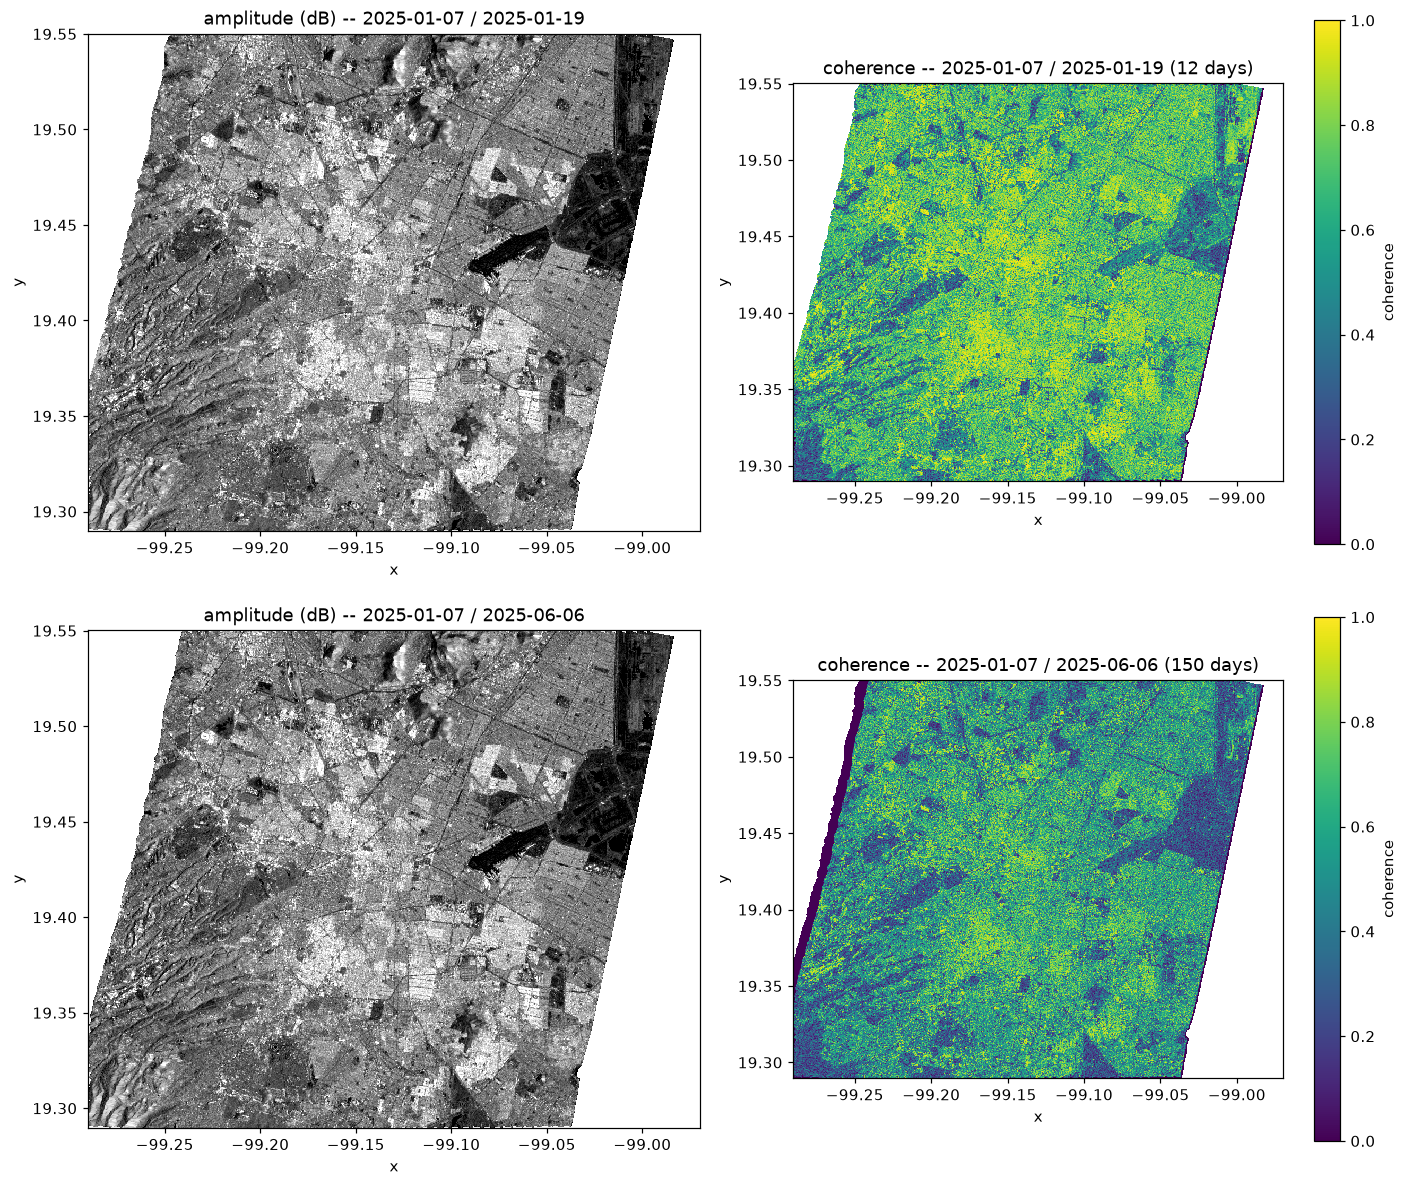

In [5]:
# Steps 5 and 6. The coherence window already averaged 3 by 10 pixels, which is
# the multilook for this notebook, so the layers stay on the debursted line grid and
# line up with t_full. terrain_correct then puts them on the DEM's map grid.

# Line count of one reference burst, before deburst. The joined image is longer than
# this; geocoding uses t_full, which already has one time per output line.
lpb = members[REF]["slc"][0].shape[0]


def geocode_pair(d):  # geocode the amplitude and coherence of one pair
    # amplitude is a field amplitude (fourth root of the product of the two powers), so
    # 20*log10 is the geometric mean of the two intensities in dB. Still uncalibrated DN.
    # terrain_correct locates every DEM cell in radar geometry (zero-Doppler time to row,
    # slant range to column) using these ellipsoidal heights, which removes foreshortening
    # and layover. The orbit is the precise state vectors loaded above.
    amp_db = (20 * np.log10(results[d]["amplitude"])).astype("float32")
    # terrain correction onto the map grid
    return sar.terrain_correct({"amplitude_db": amp_db, "coherence": results[d]["coherence"].astype("float32")},
                               t_full, near_range, range_spacing, a0["orbit"], dem_ell)


# slant_range_time is the two-way travel time of sample 0 of the full burst. c/2 turns
# that into a slant range in metres, and col0 times the range spacing shifts it to the
# first sample of the AOI crop. Both bursts were cropped to the same columns.
near_range = float(a0["slant_range_time"] * sar.SPEED_OF_LIGHT / 2 + members[REF]["col0"][0] * a0["range_pixel_spacing"])
range_spacing = a0["range_pixel_spacing"]  # slant-range pixel spacing (m)

# 1. Shortest and longest baselines: 12 days (S1A/S1A) and 150 days (S1A/S1C).
SHORT, LONG = SECONDARIES[0], SECONDARIES[-1]
geo_short, geo_long = geocode_pair(SHORT), geocode_pair(LONG)  # geocode the short and the long pair

# 2. The amplitude is uncalibrated digital numbers, so the grey scale is the 2nd to 98th
#    percentile of the short pair rather than a fixed sigma-nought range. The same limits
#    are used on the long pair so the two amplitude panels can be compared.
amp_lo, amp_hi = np.nanpercentile(geo_short["amplitude_db"], [2, 98])

# 3. Amplitude gives the scene (built-up fabric, hills, the old lake bed). Coherence is
#    drawn from 0 to 1 on both dates: bright is stable, dark has decorrelated.
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
# amplitude of the short pair
geo_short["amplitude_db"].plot(ax=axes[0, 0], cmap="gray", vmin=amp_lo, vmax=amp_hi, add_colorbar=False)
axes[0, 0].set_title(f"amplitude (dB) -- {REF} / {SHORT}")  # title
geo_short["coherence"].plot(ax=axes[0, 1], cmap="viridis", vmin=0, vmax=1)  # coherence of the short pair
axes[0, 1].set_title(f"coherence -- {REF} / {SHORT} (12 days)")  # title
# amplitude of the long pair
geo_long["amplitude_db"].plot(ax=axes[1, 0], cmap="gray", vmin=amp_lo, vmax=amp_hi, add_colorbar=False)
axes[1, 0].set_title(f"amplitude (dB) -- {REF} / {LONG}")  # title
geo_long["coherence"].plot(ax=axes[1, 1], cmap="viridis", vmin=0, vmax=1)  # coherence of the long pair
axes[1, 1].set_title(f"coherence -- {REF} / {LONG} (150 days)")  # title
for ax in axes.ravel():  # for every panel
    ax.set_aspect("equal")   # one degree of longitude and latitude drawn the same length
plt.tight_layout()  # arrange

### A coherence time series

Rather than assume where the "stable" and "changing" land cover are, the scene can speak for
itself: as temporal baseline grows, the fraction of pixels that stay usably coherent
(γ > 0.3, a common unwrapping threshold) shrinks, and the whole coherence distribution shifts
down and widens.


,baseline (days),satellite pair,median coherence,% pixels with coherence > 0.3
2025-01-19,12,S1A/S1A,0.576429,67.154530
2025-02-12,36,S1A/S1A,0.512164,64.632693
2025-04-13,96,S1A/S1A,0.435011,60.934653
2025-06-06,150,S1A/S1C,0.387308,57.527906


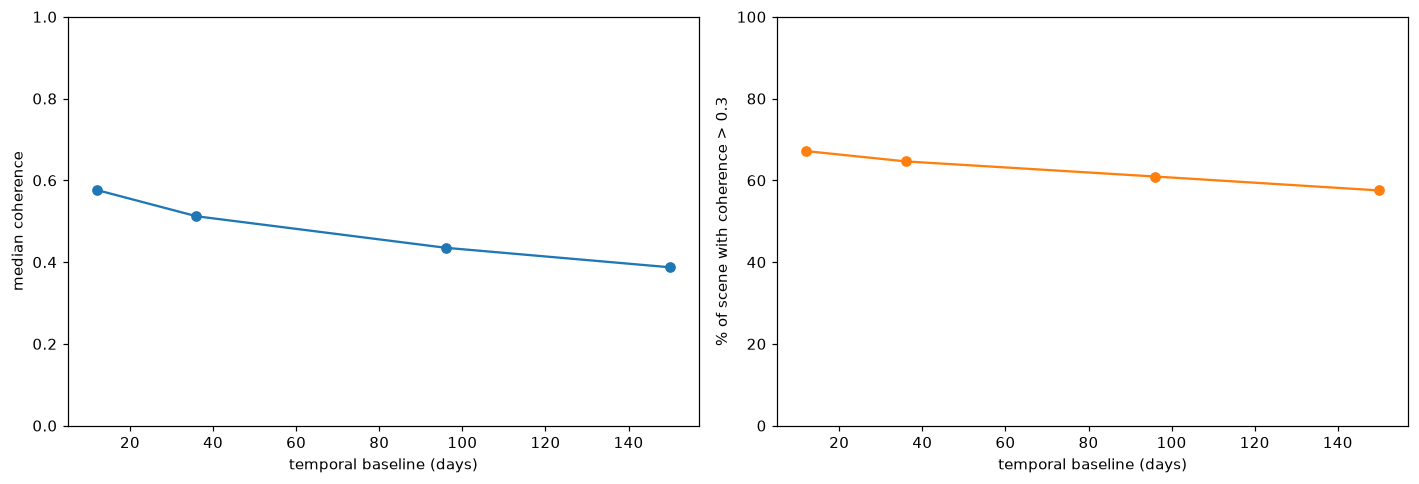

In [6]:
# Step 7. One row per pair: temporal baseline, which satellites formed it, the median
# coherence, and the share of pixels still above 0.3. That 0.3 level is a common cutoff
# before phase unwrapping; below it the phase is usually too noisy to unwrap. The
# fractions are taken on the debursted radar grid, before geocoding.

stats = pd.DataFrame({
    "baseline (days)": [(pd.Timestamp(d) - pd.Timestamp(REF)).days for d in SECONDARIES],
    # Dates before 20 May 2025 are Sentinel-1A against Sentinel-1A. 2025-06-06 is the
    # first secondary after the handover, so that pair is S1A/S1C.
    "satellite pair": [f"S1A/{'S1A' if d < '2025-05-20' else 'S1C'}" for d in SECONDARIES],
    "median coherence": [np.nanmedian(results[d]["coherence"]) for d in SECONDARIES],
    "% pixels with coherence > 0.3": [100 * np.nanmean(results[d]["coherence"] > 0.3) for d in SECONDARIES],
}, index=SECONDARIES)

# 1. Median coherence against baseline. A smooth decline is temporal decorrelation
#    (vegetation, soil moisture, small motions inside the window). A break at the
#    S1A/S1C pair would mean the ESD step had not absorbed the change of orbital tube.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
# median coherence against temporal baseline
axes[0].plot(stats["baseline (days)"], stats["median coherence"], "o-")
axes[0].set(xlabel="temporal baseline (days)", ylabel="median coherence", ylim=(0, 1))  # labels and limits
# 2. How much of the scene stays above the unwrapping threshold. Built-up pixels hold
#    coherence longer than parks and the bare ground on the surrounding hills.
axes[1].plot(stats["baseline (days)"], stats["% pixels with coherence > 0.3"], "o-", color="tab:orange")
# labels and limits
axes[1].set(xlabel="temporal baseline (days)", ylabel="% of scene with coherence > 0.3", ylim=(0, 100))
plt.tight_layout()  # arrange
stats  # show the table

## Takeaways and limitations

- `geolattice.rsense.insar.interferogram()` already implements the coherence operator at the top of
  this notebook exactly, tested against synthetic data in `tests/rsense/test_insar.py`; combined
  with `sar.read_slc_burst`/`apply_orbit_file` (Step 1), `coregister_stack` (back-geocoding + ESD,
  also Step 1), `sar.deburst` (Step 3), `sar.multilook`/`insar.multilook_complex` (Step 5) and
  `sar.terrain_correct` (Step 6), every step of the workflow above except TOPSAR-Merge has a
  real, tested implementation -- this notebook is that implementation exercised on a real stack
  rather than a new one.
- **TOPSAR-Merge (Step 4) is not implemented as a public function** and was not needed here (or
  in any other notebook in this series): every AOI used so far fits inside one sub-swath. Only a
  private two-burst annotation merge helper exists, used internally by `deburst`.
- Median coherence falls smoothly and monotonically with baseline (0.58 at 12 days to 0.39 at
  150 days), as expected for a mostly built-up but seasonally active scene (this AOI mixes
  dense urban fabric with parks, looser settlements and bare ground on the surrounding hills).
  The 2025-06-06 pair's much larger ESD correction (about -184 mm, against 6-29 mm for the
  same-satellite pairs) confirms the Sentinel-1A-to-1C handover really does add a geometric
  baseline on top of the 150-day temporal one -- but `coregister_stack`'s ESD step absorbs it
  cleanly enough that the coherence decay stays on the same smooth curve as the other three
  pairs, rather than showing a separate anomaly.
- Coherence needs no radiometric calibration (it is a normalized ratio), unlike the intensity
  features used in the dual-pol decomposition notebook -- one of relatively few SAR products
  that is this forgiving of an uncalibrated input.

#### References

- Zebker, H. A., & Villasenor, J. (1992). *Decorrelation in interferometric radar echoes.*
  IEEE Transactions on Geoscience and Remote Sensing, 30(5), 950-959.
- Bamler, R., & Hartl, P. (1998). *Synthetic aperture radar interferometry.* Inverse Problems,
  14(4), R1-R54.
- Zwieback, S., Hensley, S., & Hajnsek, I. (2015). *Assessment of soil moisture effects on
  L-band radar interferometry.* Remote Sensing of Environment, 164, 77-89. (temporal
  decorrelation sources)
